In [12]:
# КП. Цуркан Еріка. Варіант 7 (17)
import warnings
warnings.filterwarnings("ignore")
!pip install -q scikit-fuzzy networkx pygad

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import skfuzzy as fuzz
from skfuzzy import control as ctrl
from sklearn.model_selection import train_test_split
from scipy.optimize import minimize, milp, LinearConstraint, Bounds
import pygad

In [14]:
## 1. Підсистема
# 3 трикутні терми на кожну змінну, 9 правил з таблиці x \ y

TERMS = ["низький", "середній", "високий"]


def fuzzy_system(x_range, y_range, z_range, table, method):
    x = ctrl.Antecedent(np.linspace(*x_range, 201), "x")
    y = ctrl.Antecedent(np.linspace(*y_range, 201), "y")
    z = ctrl.Consequent(np.linspace(*z_range, 201), "z", defuzzify_method=method)
    for var in (x, y, z):
        var.automf(3, names=TERMS)
    rules = [ctrl.Rule(x[TERMS[i]] & y[TERMS[j]], z[table[i][j]]) for i in range(3) for j in range(3)]
    return ctrl.ControlSystemSimulation(ctrl.ControlSystem(rules))

In [15]:
## 2. Виведення за Мамдані
# точка з README: 1.1 x = 1130, y = 37.5;
# 1.2 x = 5, y = 0.5;
# виходи 1.1 і 1.2 => входи 1.3

L, M, H = TERMS

# 1.1 очікуване вироблення: інсоляція, температура панелей -> МВт*год/рік
R11 = ((800, 1400), (10, 60), (0, 1500))
T11 = [[M, L, L],
       [H, M, L],
       [H, H, M]]

# 1.2 здатність мережі прийняти: запас потужності, відхилення напруги -> бали
R12 = ((0, 10), (0, 10), (0, 10))
T12 = [[M, L, L],
       [H, M, L],
       [H, H, M]]

# 1.3 допустима потужність приєднання: вироблення, здатність мережі -> МВт
R13 = ((0, 1500), (0, 10), (0, 10))
T13 = [[L, L, M],
       [L, M, H],
       [M, H, H]]


def infer(ranges, table, x_val, y_val, method="centroid"):
    sim = fuzzy_system(*ranges, table, method)
    sim.input["x"], sim.input["y"] = x_val, y_val
    sim.compute()
    return sim.output["z"]


out11 = infer(R11, T11, 1130, 37.5)
out12 = infer(R12, T12, 5, 0.5)
out13_c = infer(R13, T13, out11, out12, "centroid")
out13_m = infer(R13, T13, out11, out12, "mom")

print("1.1 очікуване вироблення, МВт*год/рік:", round(out11, 2))
print("1.2 здатність мережі прийняти, бали:", round(out12, 3))
print("1.3 допустима потужність, МВт: центроїд", round(out13_c, 3), "| середнє максимумів", round(out13_m, 3))

1.1 очікуване вироблення, МВт*год/рік: 750.0
1.2 здатність мережі прийняти, бали: 7.382
1.3 допустима потужність, МВт: центроїд 5.539 | середнє максимумів 5.0


In [16]:
## 2. Сила правил 1.3
# ступінь належності кожного входу до терма; сила правила = min(x, y)


def memberships(value_, low, high):
    uni = np.linspace(low, high, 201)
    mid = (low + high) / 2
    shapes = {L: [low, low, mid], M: [low, mid, high], H: [mid, high, high]}
    return {term: float(fuzz.interp_membership(uni, fuzz.trimf(uni, abc), value_)) for term, abc in shapes.items()}


mu_x = memberships(out11, *R13[0])
mu_y = memberships(out12, *R13[1])
print("x =", round(out11, 2), {k: round(m, 3) for k, m in mu_x.items()})
print("y =", round(out12, 3), {k: round(m, 3) for k, m in mu_y.items()})

strength = pd.DataFrame([(TERMS[i], TERMS[j], T13[i][j], min(mu_x[TERMS[i]], mu_y[TERMS[j]]))
                         for i in range(3) for j in range(3)],
                        columns=["x", "y", "z", "сила"]).sort_values("сила", ascending=False)
display(strength.round(3))

x = 750.0 {'низький': 0.0, 'середній': 1.0, 'високий': 0.0}
y = 7.382 {'низький': 0.0, 'середній': 0.524, 'високий': 0.476}


,x,y,z,сила
4,середній,середній,середній,0.524
5,середній,високий,високий,0.476
0,низький,низький,низький,0.000
2,низький,високий,середній,0.000
1,низький,середній,низький,0.000
3,середній,низький,низький,0.000
6,високий,низький,середній,0.000
7,високий,середній,високий,0.000
8,високий,високий,високий,0.000


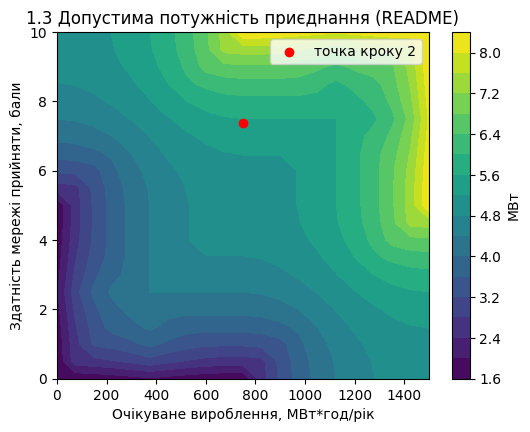

In [17]:
## 3. Поверхня 1.3
# вихід (центроїд) на сітці 21 * 21

xs = np.linspace(*R13[0], 21)
ys = np.linspace(*R13[1], 21)


def surface(table):
    return np.array([[infer(R13, table, xv, yv) for xv in xs] for yv in ys])


def draw(Z, title, cmap="viridis"):
    plt.figure(figsize=(6, 4.5))
    plt.contourf(xs, ys, Z, levels=20, cmap=cmap)
    plt.colorbar(label="МВт")
    plt.scatter([out11], [out12], color="red", label="точка кроку 2")
    plt.xlabel("Очікуване вироблення, МВт*год/рік")
    plt.ylabel("Здатність мережі прийняти, бали")
    plt.title(title)
    plt.legend()
    plt.show()


Z_old = surface(T13)
draw(Z_old, "1.3 Допустима потужність приєднання (README)")

,центроїд,середнє максимумів
правила з README,5.539,5.0
зі зміненим правилом,8.077,8.8


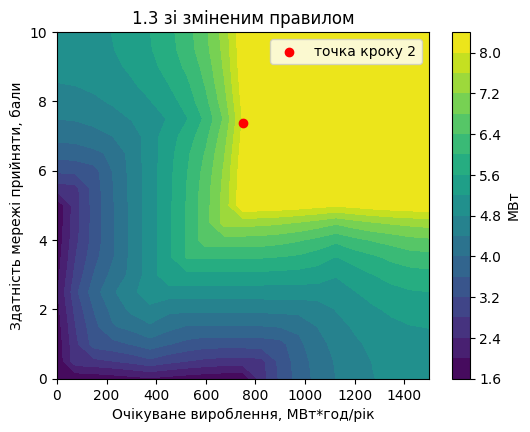

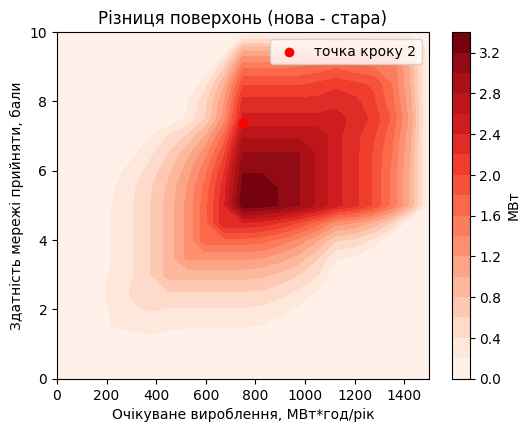

найбільша різниця на сітці, МВт: 3.333


In [18]:
## 4. Одне правило
# 1.3: x середній, y середній => «середній» замінюємо на «високий» (у копії таблиці)

T13_new = [row[:] for row in T13]
T13_new[1][1] = H

new_c = infer(R13, T13_new, out11, out12, "centroid")
new_m = infer(R13, T13_new, out11, out12, "mom")
display(pd.DataFrame({"центроїд": [out13_c, new_c], "середнє максимумів": [out13_m, new_m]},
                     index=["правила з README", "зі зміненим правилом"]).round(3))

Z_new = surface(T13_new)
draw(Z_new, "1.3 зі зміненим правилом")
draw(Z_new - Z_old, "Різниця поверхонь (нова - стара)", cmap="Reds")
print("найбільша різниця на сітці, МВт:", round((Z_new - Z_old).max(), 3))

In [19]:
## 5. Дані
# нормування min-max за навчальною частиною; точка відліку - прогноз середнім

sample = pd.read_csv("sample.csv")
X = sample.iloc[:, :-1]
y = sample.iloc[:, -1]

X_tr, X_te, y_tr, y_te = train_test_split(X.to_numpy(), y.to_numpy(), test_size=0.25, random_state=0)

x_min, x_max = X_tr.min(axis=0), X_tr.max(axis=0)
x_tr, x_te = (X_tr - x_min) / (x_max - x_min), (X_te - x_min) / (x_max - x_min)
y_span = y_tr.max() - y_tr.min()
t_tr, t_te = (y_tr - y_tr.min()) / y_span, (y_te - y_tr.min()) / y_span

base_tr = np.sqrt(np.mean((y_tr - y_tr.mean()) ** 2))
base_te = np.sqrt(np.mean((y_te - y_tr.mean()) ** 2))
print("рядків: навчальна", len(X_tr), "| тестова", len(X_te))
print("RMSE прогнозу середнім, тис. грн: навчальна", round(base_tr, 4), "| тестова", round(base_te, 4))

рядків: навчальна 45 | тестова 16
RMSE прогнозу середнім, тис. грн: навчальна 1.211 | тестова 1.243


In [20]:
def unpack(theta, c):
    k = c * x_tr.shape[1]
    return theta[:k].reshape(c, -1), np.exp(theta[k:2 * k]).reshape(c, -1), theta[2 * k:]


def activation(theta, x, c):
    centers, widths, _ = unpack(theta, c)
    z = -0.5 * (((x[:, None, :] - centers[None]) / widths[None]) ** 2).sum(axis=2)
    e = np.exp(z - z.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)


def rmse(theta, x, t, c):
    return float(np.sqrt(np.mean((activation(theta, x, c) @ unpack(theta, c)[2] - t) ** 2)))


def errors(theta, c):
    return rmse(theta, x_tr, t_tr, c) * y_span, rmse(theta, x_te, t_te, c) * y_span


def pack(centers, widths):
    c = len(centers)
    theta = np.concatenate([np.ravel(centers), np.log(np.ravel(widths)), np.zeros(c)])
    w = activation(theta, x_tr, c)
    theta[2 * c * x_tr.shape[1]:] = np.linalg.solve(w.T @ w + 1e-8 * np.eye(c), w.T @ t_tr)
    return theta


def tune(theta, c):
    n = c * x_tr.shape[1]
    bounds = [(-0.05, 1.05)] * n + [(np.log(0.08), np.log(0.8))] * n + [(-0.05, 1.05)] * c
    res = minimize(rmse, np.clip(theta, *np.array(bounds).T), args=(x_tr, t_tr, c),
                   method="L-BFGS-B", bounds=bounds, options={"maxiter": 2000})
    return res.x

In [21]:
def subclust(data, ra, accept=0.5, reject=0.15):
    a, b = 4 / ra ** 2, 4 / (1.5 * ra) ** 2
    potential = np.exp(-a * ((data[:, None, :] - data[None, :, :]) ** 2).sum(-1)).sum(1)
    first, centers = potential.max(), []
    while True:
        k = int(potential.argmax())
        top = potential[k]
        if top < reject * first:
            break
        if top < accept * first:
            nearest = min(np.sqrt(((data[k] - data[c]) ** 2).sum()) for c in centers)
            if nearest / ra + top / first < 1:
                potential[k] = 0
                continue
        centers.append(k)
        potential = np.maximum(potential - top * np.exp(-b * ((data - data[k]) ** 2).sum(1)), 0)
    return data[centers]

In [22]:
## 6. Субтрактивна кластеризація
# менший ra => більше правил

data_tr = np.column_stack([x_tr, t_tr])
for ra in [0.3, 0.5, 0.8]:
    print(f"ra = {ra}: правил", len(subclust(data_tr, ra)))

ra = 0.3: правил 21
ra = 0.5: правил 3
ra = 0.8: правил 2


In [23]:
## 7. Правила з c-means і налаштування
# ширина = std точок від центру, зважене u2; потім tune підганяє всі параметри


def cmeans_rules(c):
    cntr, u, *_ = fuzz.cluster.cmeans(np.column_stack([x_tr, t_tr]).T, c=c, m=2.0, error=1e-6, maxiter=1000, seed=0)
    centers = cntr[:, :x_tr.shape[1]]
    widths = np.array([np.sqrt((u[k] ** 2 @ (x_tr - centers[k]) ** 2) / (u[k] ** 2).sum()) for k in range(c)])
    return pack(centers, np.clip(widths, 0.08, 0.8))


theta = cmeans_rules(3)
theta_tuned = tune(theta, 3)

display(pd.DataFrame([[base_tr, base_te], errors(theta, 3), errors(theta_tuned, 3)],
                     columns=["навчальна", "тестова"],
                     index=["прогноз середнім", "3 правила, до налаштування", "3 правила, після налаштування"]).round(4))

,навчальна,тестова
прогноз середнім,1.2110,1.2430
"3 правила, до налаштування",1.0983,1.3287
"3 правила, після налаштування",0.6435,1.3519


,навчальна,тестова,розрив
правил,,,
2,0.7662,1.2962,0.5300
3,0.6435,1.3519,0.7083
4,0.5738,1.2344,0.6606
5,0.5632,1.5551,0.9919
6,0.4856,1.5853,1.0997


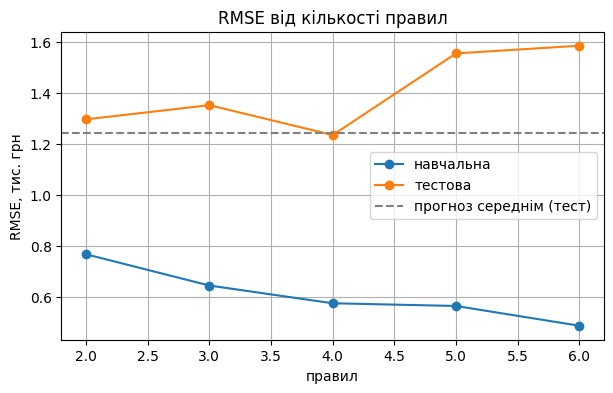

In [24]:
## 8. Кількість правил
# 2–6 правил після налаштування; розрив = тестова - навчальна

by_rules = pd.DataFrame([errors(tune(cmeans_rules(c), c), c) for c in range(2, 7)],
                        index=pd.Index(range(2, 7), name="правил"), columns=["навчальна", "тестова"])
by_rules["розрив"] = by_rules["тестова"] - by_rules["навчальна"]
display(by_rules.round(4))

by_rules[["навчальна", "тестова"]].plot(marker="o", grid=True, figsize=(7, 4), title="RMSE від кількості правил")
plt.axhline(base_te, color="gray", linestyle="--", label="прогноз середнім (тест)")
plt.ylabel("RMSE, тис. грн")
plt.legend()
plt.show()

In [25]:
## 9. Задача про бригади
# фонди 8, 7, 3 год; t = 0.5 + contracted_power_kw / 12; v - service_cost_kuah

FUND = (8, 7, 3)
TIME_DIV = 12

t = (0.5 + sample["contracted_power_kw"] / TIME_DIV).to_numpy()
v = sample.iloc[:, -1].to_numpy()
print("об'єктів:", len(t), "| сумарний час, год:", round(t.sum(), 2), "| фонд, год:", sum(FUND))

об'єктів: 61 | сумарний час, год: 134.41 | фонд, год: 18


In [26]:
def load(plan):
    return [float(t[plan == b].sum()) for b in (1, 2, 3)]


def overflow(plan):
    return float(sum(max(0.0, used - f) for used, f in zip(load(plan), FUND)))


def value(plan):
    return float(v[plan > 0].sum())


def repair(plan):
    plan = np.asarray(plan, int).copy()
    for b, f in enumerate(FUND, start=1):
        idx = np.flatnonzero(plan == b)
        used = t[idx].sum()
        for i in idx[np.argsort(v[idx] / t[idx])]:
            if used <= f + 1e-9:
                break
            plan[i], used = 0, used - t[i]
    return plan

In [27]:
## 9. Жадібний алгоритм
# за спаданням v / t, у першу бригаду, де ще вміщується


def report(name, plan):
    print(f"{name}: сума {value(plan):.3f} тис. грн | завантаження {[round(x, 2) for x in load(plan)]} год | перевищення {overflow(plan):.2f} год")


plan_greedy = np.zeros(len(t), dtype=int)
used = [0.0, 0.0, 0.0]
for i in np.argsort(-(v / t)):
    for b in range(3):
        if used[b] + t[i] <= FUND[b] + 1e-9:
            plan_greedy[i] = b + 1
            used[b] += t[i]
            break

report("жадібний", plan_greedy)

жадібний: сума 34.656 тис. грн | завантаження [7.65, 6.62, 2.7] год | перевищення 0.00 год


In [28]:
## 10. ГА з ремонтом
# пристосованість = сума полагодженого плану

def run_ga(fitness):
    ga = pygad.GA(num_generations=250, sol_per_pop=120, num_parents_mating=60, num_genes=len(t), gene_type=int,
                  gene_space=[0, 1, 2, 3], fitness_func=fitness, parent_selection_type="tournament", K_tournament=3,
                  crossover_type="uniform", mutation_type="random", mutation_num_genes=max(1, len(t) // 20),
                  keep_elitism=4, random_seed=0, suppress_warnings=True)
    ga.run()
    return np.asarray(ga.best_solution()[0], int)


plan_repair = repair(run_ga(lambda ga, sol, idx: value(repair(sol))))
report("ГА з ремонтом", plan_repair)

ГА з ремонтом: сума 34.934 тис. грн | завантаження [7.88, 6.85, 2.7] год | перевищення 0.00 год


In [29]:
## 10. ГА зі штрафом
# пристосованість = сума − 10 · перевищення; план не ремонтуємо

plan_penalty = run_ga(lambda ga, sol, idx: value(sol) - 10 * overflow(sol))
report("ГА зі штрафом", plan_penalty)

ГА зі штрафом: сума 27.951 тис. грн | завантаження [8.33, 6.61, 1.83] год | перевищення 0.33 год


In [30]:
def optimum():
    n = len(t)
    rows = [np.concatenate([t if b == k else np.zeros(n) for k in range(3)]) for b in range(3)]
    rows += [np.tile(np.eye(n)[i], 3) for i in range(n)]
    res = milp(-np.tile(v, 3), integrality=np.ones(3 * n), bounds=Bounds(0, 1),
               constraints=LinearConstraint(np.array(rows), [0] * (3 + n), list(FUND) + [1] * n))
    return (np.arange(1, 4)[:, None] * np.round(res.x).reshape(3, n)).sum(0).astype(int)

In [31]:
## 11. Точний оптимум і порівняння

plan_optimum = optimum()
plans = {"жадібний алгоритм": plan_greedy, "ГА з ремонтом": plan_repair,
         "ГА зі штрафом": plan_penalty, "оптимум": plan_optimum}
best = value(plan_optimum)
display(pd.DataFrame([(name, round(value(p), 3), [round(x, 2) for x in load(p)], round(overflow(p), 2),
                       round(100 * value(p) / best, 2)) for name, p in plans.items()],
                     columns=["план", "сума, тис. грн", "завантаження, год", "перевищення, год", "% оптимуму"]).set_index("план"))

,"сума, тис. грн","завантаження, год","перевищення, год",% оптимуму
план,,,,
жадібний алгоритм,34.656,"[7.65, 6.62, 2.7]",0.00,98.47
ГА з ремонтом,34.934,"[7.88, 6.85, 2.7]",0.00,99.26
ГА зі штрафом,27.951,"[8.33, 6.61, 1.83]",0.33,79.42
оптимум,35.196,"[7.94, 6.95, 2.86]",0.00,100.00


In [32]:
## Double-check
plan = pd.DataFrame({"row": np.arange(len(t)), "brigade": np.asarray(plan_repair, int)})

assert len(t) == len(v) == len(plan) == len(sample), "t, v і план мають мати рядок на кожен об'єкт sample.csv"
assert tuple(FUND) in [(6, 6, 6), (7, 6, 5), (7, 7, 4), (8, 5, 5), (8, 6, 4), (8, 7, 3), (9, 5, 4), (9, 6, 3), (10, 4, 4), (10, 5, 3)] and TIME_DIV in (8, 10, 12), "фонди бригад і дільник — з README варіанта, фонди в порядку бригад 1, 2, 3"
assert plan["brigade"].isin([0, 1, 2, 3]).all(), "бригада — 0, 1, 2 або 3"
assert overflow(plan_repair) == 0, "план ГА з ремонтом перевищує фонд часу"
assert value(plan_repair) >= value(plan_greedy) - 1e-9, "ГА з ремонтом гірший за жадібний алгоритм: перевірте параметри з кроку 10"
assert value(plan_repair) <= value(plan_optimum) + 1e-9, "сума більша за оптимум: перевірте t, v і FUND"
assert errors(theta_tuned, 3)[0] < errors(theta, 3)[0], "налаштування не знизило навчальну похибку"

plan.to_csv("plan.csv", index=False)
print("усе гаразд: сума", round(value(plan_repair), 3), "з оптимуму", round(value(plan_optimum), 3))

усе гаразд: сума 34.934 з оптимуму 35.196
